raw = pd.read_csv(DATA_RAW, parse_dates=["Date"])
df = raw[(raw["City"] == CITY) & raw["Date"].between(WINDOW_START, WINDOW_END)].copy()
df = df.dropna(subset=["PM2.5", "AQI"])
print(df.shape)
# At Gate M1, replace all of the above with:  df = load_clean()

In [2]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from sklearn.model_selection import train_test_split
from src.utils import *
set_plot_style()
print("setup ok")

setup ok


In [3]:
raw = pd.read_csv(DATA_RAW, parse_dates=["Date"])
df = raw[(raw["City"] == CITY) & raw["Date"].between(WINDOW_START, WINDOW_END)].copy()
df = df.dropna(subset=["PM2.5", "AQI"])
print(df.shape)
df[["Date", "PM2.5", "AQI"]].head()

(1815, 16)


,Date,PM2.5,AQI
10229,2015-01-01,313.22,472.0
10230,2015-01-02,186.18,454.0
10231,2015-01-03,87.18,143.0
10232,2015-01-04,151.84,319.0
10233,2015-01-05,146.60,325.0


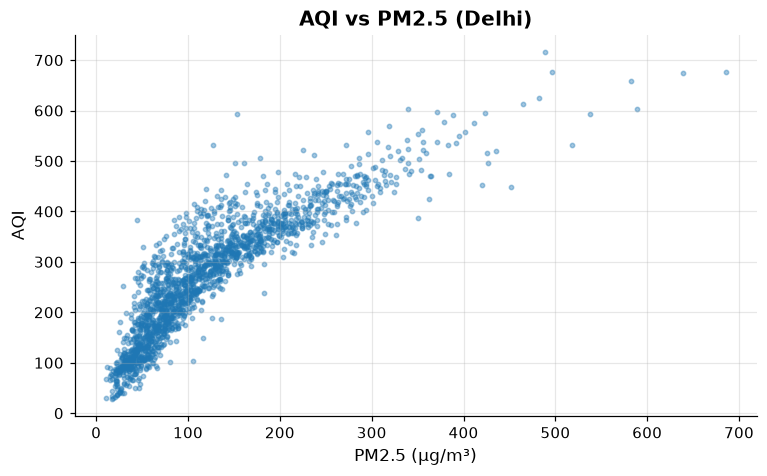

,PM2.5,AQI
PM2.5,1.000000,0.877582
AQI,0.877582,1.000000


In [4]:
fig, ax = plt.subplots()
ax.scatter(df["PM2.5"], df["AQI"], s=8, alpha=.4)
ax.set(title="AQI vs PM2.5 (Delhi)", xlabel="PM2.5 (µg/m³)", ylabel="AQI")
plt.show()
df[["PM2.5", "AQI"]].corr()

In [5]:
train, test = train_test_split(df, test_size=TEST_SIZE, random_state=SEED)
X_train = sm.add_constant(train[["PM2.5"]])
model = sm.OLS(train["AQI"], X_train).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                    AQI   R-squared:                       0.773
Model:                            OLS   Adj. R-squared:                  0.773
Method:                 Least Squares   F-statistic:                     4952.
Date:                Mon, 12 Oct 2026   Prob (F-statistic):               0.00
Time:                        09:39:52   Log-Likelihood:                -7940.4
No. Observations:                1452   AIC:                         1.588e+04
Df Residuals:                    1450   BIC:                         1.590e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        113.7549      2.652     42.896      0.0